In [1]:
import pandas as pd

data = pd.read_csv("data/ChargePointData2011-2020-ManullyPreCleaned3.csv", low_memory=False)
data

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,03:03:32,01:54:03,...,-122.160309,USD,0.00,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,00:02:06,00:01:54,...,-122.160309,USD,0.00,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,04:17:32,04:17:28,...,-122.160309,USD,0.00,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,02:03:24,02:02:58,...,-122.160309,USD,0.00,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,01:11:24,00:43:54,...,-122.160309,USD,0.00,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259410,PALO ALTO CA / TED THOMPSON #3,0024:B100:0002:9F81,City of Palo Alto,12/31/2020 16:39,PST,12/31/2020 17:14,PST,12/31/2020 17:16,00:35:44,00:35:18,...,-122.144043,USD,0.42,Plug Out at Vehicle,2369,94301.0,2024201,NaN,1.750000e+11,CT4020-HD-GW
259411,PALO ALTO CA / WEBSTER #1,0024:B100:0002:4233,City of Palo Alto,12/31/2020 16:48,PST,12/31/2020 20:31,PST,12/31/2020 20:32,03:43:01,02:14:04,...,-122.158272,USD,4.69,Plug Out at Vehicle,7255,94541.0,242661,Santa Clara County,1.340000e+11,CT4020-HD-GW
259412,PALO ALTO CA / MPL #4,0024:B100:0003:CD37,City of Palo Alto,12/31/2020 17:28,PST,1/1/2021 10:56,PST,1/1/2021 10:57,17:28:14,05:08:12,...,-122.113510,USD,6.82,Plug Out at Vehicle,455,94306.0,449995,Santa Clara County,2.000000e+11,CT4010-HD-GW
259413,PALO ALTO CA / WEBSTER #1,0024:B100:0002:4233,City of Palo Alto,12/31/2020 17:49,PST,12/31/2020 21:55,PST,12/31/2020 21:56,04:05:34,03:53:42,...,-122.158272,USD,2.75,Plug Out at Vehicle,7256,94552.0,804075,Santa Clara County,1.340000e+11,CT4020-HD-GW


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259207 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

In [3]:
# What does the latitude and longitude represent? It is not equal to each station
'''
Feature engineer turn Start Date into:
# Hour of Day: Captures peak commute times.
# Day of Week: Captures the difference between a Monday workday and a Sunday leisure day.
# Month/Season: Captures holiday travel or weather-related usage.
# Is Weekend: A binary flag (0 or 1) that simplifies the weekend pattern for the model (?)
# Is holiday: 
機器學習用上面的數據，也用：
# MAC Address
# Port Type / Plug Type: Some cars only use specific plugs; if a station has a rare plug, it might be less busy.
# Fee: As seen in your data correlation (~0.33), the price often influences how long people stay. Higher fees sometimes lead to shorter total durations.
# Charging Time (hh:mm:ss)
# Note: Port Type missing some values, but just 9
# Extra note: Other column not on remove data list will be used as well (?)

Data that could be important
# Fee
# Energy (kWh) (?): Data leak

Remove data that is not important to the model
# Port type and plug type is the same (each data equal to each other), so just pick one, I picked plug type (port type missing values)
# Station name, Org Name, Start Time Zone, End Date, End Time Zone, Transaction Date (Pacific Time), 
# EVSE ID, Address 1, City, State/Province, Postal Code, Country, Country
# Longitude, latitude
# Currency, Ended By, Plug In Event Id, Driver Postal Code, User ID, System S/N, Model Number
# Port Number (?),


Label: Total Duration

Two ways to approach:
Classification First: Predict a binary label: Available (0) or Occupied (1).
# How to get data that gives the label 0? Just get random time in the world?
# Calculate how many rows you have for Label 1. Generate the exact same number of rows for Label 0 by sampling repeatedly from your gaps by 
Negative Sampling (If a station is empty from 2:00 PM to 4:00 PM, you can create a training row for "3:00 PM" with a label of 0).
# Use Strategic Distribution Sampling ensures your training data has plenty of examples of "Available at 3:00 AM," "Available at 4:00 AM," etc. 
Flow
# Model A (Classifier): Asks "Is there a line?".
# Conditional Logic: If No (0), Wait Time = 0. If Yes (1), call Model B.
# Model B (Regressor): Asks "Since there is a line, how long until the current session ends?".

Regression Second: If the station is predicted to be occupied, run a second model to predict the Remaining Total Duration based on the features above
This is generally the standard for IT and Engineering projects because it mirrors real-world decision-making

Save the MAC and keys (Port Type / Plug Type, Fee, Average Energy per Session) even future events on another database, so it can be called
when putting inputs called
'''

'\nFeature engineer turn Start Date into:\n# Hour of Day: Captures peak commute times.\n# Day of Week: Captures the difference between a Monday workday and a Sunday leisure day.\n# Month/Season: Captures holiday travel or weather-related usage.\n# Is Weekend: A binary flag (0 or 1) that simplifies the weekend pattern for the model (?)\n# Is holiday: \n機器學習用上面的數據，也用：\n# MAC Address\n# Port Type / Plug Type: Some cars only use specific plugs; if a station has a rare plug, it might be less busy.\n# Fee: As seen in your data correlation (~0.33), the price often influences how long people stay. Higher fees sometimes lead to shorter total durations.\n# Charging Time (hh:mm:ss)\n# Note: Port Type missing some values, but just 9\n# Extra note: Other column not on remove data list will be used as well (?)\n\nData that could be important\n# Fee\n# Energy (kWh) (?): Data leak\n\nRemove data that is not important to the model\n# Port type and plug type is the same (each data equal to each other), 

## Feature Engineering

In [4]:
import pandas as pd
import numpy as np
import requests
from pandas.tseries.holiday import USFederalHolidayCalendar

# --- 1. WEATHER UTILITY ---
def get_palo_alto_weather(start_date, end_date):
    """Fetches hourly historical weather for Palo Alto from Open-Meteo."""
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": 37.4419,
        "longitude": -122.1430,
        "start_date": start_date.strftime('%Y-%m-%d'),
        "end_date": end_date.strftime('%Y-%m-%d'),
        "hourly": ["temperature_2m", "precipitation", "cloudcover"],
        "timezone": "America/Los_Angeles"
    }
    try:
        response = requests.get(url, params=params)
        res_data = response.json()
        weather_df = pd.DataFrame({
            'weather_time': pd.to_datetime(res_data['hourly']['time']),
            'temp': res_data['hourly']['temperature_2m'],
            'precip': res_data['hourly']['precipitation'],
            'clouds': res_data['hourly']['cloudcover']
        })
        return weather_df
    except Exception as e:
        print(f"Weather API error: {e}. Returning empty DF.")
        return pd.DataFrame()

# --- 2. TIME UTILITIES ---
def to_seconds_vectorized(series):
    """Converts hh:mm:ss to total seconds."""
    temp = series.str.split(':', expand=True).astype(float)
    return (temp[0] * 3600) + (temp[1] * 60) + temp[2]

def engineer_time_features(df):
    """Extracts temporal signals and handles cyclical encoding."""
    # Ensure datetime format for extraction
    df['Start Date'] = pd.to_datetime(df['Start Date'])
    
    # 1. Basic Extraction
    df['Minute'] = df['Start Date'].dt.minute
    df['Hour'] = df['Start Date'].dt.hour
    df['DayOfWeek'] = df['Start Date'].dt.dayofweek
    df['Month'] = df['Start Date'].dt.month
    df['IsWeekend'] = (df['DayOfWeek'] >= 5).astype(int)
    
    # 2. Holiday Lookup (US)
    cal = USFederalHolidayCalendar()
    holidays = cal.holidays(start=df['Start Date'].min(), end=df['Start Date'].max())
    df['IsHoliday'] = df['Start Date'].dt.normalize().isin(holidays).astype(int)
    
    # 3. Cyclical Encoding (Neural Network friendly)
    df['Hour_Sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
    df['Hour_Cos'] = np.cos(2 * np.pi * df['Hour'] / 24)
    df['Month_Sin'] = np.sin(2 * np.pi * df['Month'] / 12)
    df['Month_Cos'] = np.cos(2 * np.pi * df['Month'] / 12)
    
    return df

# Open-Meteo cloudcover is 0–100; spec thresholds use 0.0–1.0
_CLOUD_FRACTION_SCALE = 100.0
_LIGHT_PRECIP_MM = 2.5
_COMFORT_TEMP_C = 22.5


def get_major_public_holidays(start, end, calendar=None):
    cal = calendar or USFederalHolidayCalendar()
    pad = pd.Timedelta(days=400)
    holidays = cal.holidays(start=start - pad, end=end + pad)
    return pd.DatetimeIndex(holidays).normalize().unique().values.astype("datetime64[D]")


def add_holiday_proximity_features(df, holidays=None):
    session_days = pd.to_datetime(df["Start Date"]).dt.normalize().values.astype("datetime64[D]")
    if holidays is None:
        holidays = get_major_public_holidays(
            pd.Timestamp(session_days.min()), pd.Timestamp(session_days.max())
        )
    next_idx = np.searchsorted(holidays, session_days, side="right")
    prev_idx = next_idx - 1
    days_until = np.empty(len(session_days), dtype=np.int64)
    has_next = next_idx < len(holidays)
    days_until[has_next] = (holidays[next_idx[has_next]] - session_days[has_next]).astype(int)
    days_until[~has_next] = (holidays[-1] - session_days[~has_next]).astype(int)
    days_since = np.empty(len(session_days), dtype=np.int64)
    has_prev = prev_idx >= 0
    days_since[has_prev] = (session_days[has_prev] - holidays[prev_idx[has_prev]]).astype(int)
    days_since[~has_prev] = (session_days[~has_prev] - holidays[0]).astype(int)
    df["Days_Until_Next_Holiday"] = days_until
    df["Days_Since_Last_Holiday"] = days_since
    return df


def _cloud_cover_fraction(clouds):
    clouds = clouds.astype(float)
    if clouds.max() > 1.0:
        return clouds / _CLOUD_FRACTION_SCALE
    return clouds


def _parasitic_load_probability_index(temp, precip, light_precip_mm=_LIGHT_PRECIP_MM):
    no_precip = precip <= 0
    light_precip = (precip > 0) & (precip <= light_precip_mm)
    active_precip = precip > 0
    extreme = (temp <= 0) & active_precip
    high = (~extreme) & ((temp < 5) | (temp > 30))
    moderate = (~extreme) & (~high) & (((temp >= 5) & (temp < 15)) | light_precip)
    low = (~extreme) & (~high) & (~moderate) & ((temp >= 15) & (temp <= 25) & no_precip)
    default = ~(extreme | high | moderate | low)
    return np.select([extreme, high, moderate, low, default], [3, 2, 1, 0, 1], default=1).astype(int)


def engineer_advanced_features(df):
    df = add_holiday_proximity_features(df)
    temp = df["temp"].astype(float)
    precip = df["precip"].fillna(0).astype(float)
    clouds_frac = _cloud_cover_fraction(df["clouds"].fillna(0))
    df["Thermal_Deviation_Index"] = (temp - _COMFORT_TEMP_C).abs()
    df["Is_Freezing_Penalty"] = (temp <= 0).astype(int)
    df["Extreme_Heat_Throttle_Risk"] = (temp >= 35).astype(int)
    df["Solar_Irradiance_Proxy"] = ((temp > 30) & (clouds_frac < 0.2)).astype(int)
    df["Parasitic_Load_Probability_Index"] = _parasitic_load_probability_index(temp, precip)
    return df

def add_real_time_metadata(df, raw_data):
    # 1. Station Density (How many chargers at this physical location?)
    # This is a static "Right Now" input.
    addr_map = raw_data.groupby('Address 1')['MAC Address'].nunique().to_dict()
    df['Station_Density'] = df['Address 1'].map(addr_map)

    # 2. Pricing Signal (Is it free?)
    # Paid stations have different turnover rates.
    fee_map = raw_data.groupby('MAC Address')['Fee'].mean().apply(lambda x: 1 if x > 0 else 0).to_dict()
    df['Is_Paid_Station'] = df['MAC Address'].map(fee_map)
    
    # Need to be calculated on training set
    # hist_stats = df.groupby(['MAC Address', 'DayOfWeek', 'Hour'])['Availability'].mean().reset_index()
    # hist_stats.rename(columns={'Availability': 'Hist_Occupancy_Prob'}, inplace=True)
    # df = df.merge(hist_stats, on=['MAC Address', 'DayOfWeek', 'Hour'], how='left')
    
    return df
    
def add_fee_from_price_tier(df, raw_data, price_path="data/unit_price_by_station_palo_alto.csv"):
    """Add ``fee`` from ``price_tier`` in unit_price_by_station_palo_alto.csv (via Station Name)."""
    price_df = pd.read_csv(price_path)
    tier_by_station = price_df.set_index("Station Name")["price_tier"]
    mac_to_station = raw_data.groupby("MAC Address")["Station Name"].first()
    df["fee"] = df["MAC Address"].map(mac_to_station).map(tier_by_station)
    return df

# --- 3. MAIN PIPELINE ---
def build_final_dataset(data, availability=True):
    """Processes raw sessions, adds availability gaps, merges weather, and balances classes."""
    df = data.copy()
    df['Start Date'] = pd.to_datetime(df['Start Date'])
    df['End Date'] = pd.to_datetime(df['End Date'])
    
    # Sort for gap detection
    df = df.sort_values(['MAC Address', 'Start Date'])
    
    # A. Extract Occupied Sessions (Label 1)
    occupied = df[['MAC Address', 'Start Date', 'End Date', 'Plug Type', 'Address 1']].copy()
    occupied['Total_Duration_Secs'] = to_seconds_vectorized(df['Total Duration (hh:mm:ss)'])
    occupied['Availability'] = 1
    
    # B. Generate Available Sessions (Label 0)
    if availability:
        available_rows = []
        for mac, group in df.groupby('MAC Address'):
            group = group.sort_values('Start Date')
            for i in range(len(group) - 1):
                curr_end = group.iloc[i]['End Date']
                next_start = group.iloc[i+1]['Start Date']
                
                # Identify idle gaps longer than 5 mins
                if next_start > curr_end + pd.Timedelta(minutes=5):
                    available_rows.append({
                        'MAC Address': mac,
                        'Start Date': curr_end,
                        'End Date': next_start,
                        'Plug Type': group.iloc[i]['Plug Type'],
                        'Address 1': group.iloc[i]['Address 1'],
                        'Total_Duration_Secs': (next_start - curr_end).total_seconds(),
                        'Availability': 0
                    })
    
        available_df = pd.DataFrame(available_rows)
    
    # C. Random Undersampling for 50/50 Balance
        n_min = min(len(occupied), len(available_df))
        occupied_balanced = occupied.sample(n=n_min, random_state=42)
        available_balanced = available_df.sample(n=n_min, random_state=42)
    
    full_df = pd.concat([occupied_balanced, available_balanced], ignore_index=True)
    full_df = full_df.sort_values('Start Date').reset_index(drop=True)
    
    # D. Integrate Weather
    print("Fetching Palo Alto weather data...")
    weather = get_palo_alto_weather(full_df['Start Date'].min(), full_df['Start Date'].max())
    
    if not weather.empty:
        # Use 'h' for hourly floor (Pandas 3.0+ compatibility)
        full_df['merge_hour'] = full_df['Start Date'].dt.floor('h')
        full_df = full_df.merge(weather, left_on='merge_hour', right_on='weather_time', how='left')
        full_df.drop(columns=['merge_hour', 'weather_time'], inplace=True)
    
    # E. Feature Engineering
    full_df = engineer_time_features(full_df)
    full_df = engineer_advanced_features(full_df)
    
    # F. Encode Categoricals
    full_df['Plug Type Encoded'] = full_df['Plug Type'].map({'J1772': 0, 'NEMA 5-20R': 1}).fillna(0).astype(int)
    
    # G. Add static metadata before dropping address/session columns (it reduced the accuracy)
    # full_df = add_real_time_metadata(full_df, data)
    full_df = add_fee_from_price_tier(full_df, data)
    
    # H. Final Cleanup
    cols_to_drop = ['Start Date', 'End Date', 'Plug Type', 'Address 1']
    final_df = full_df.drop(columns=cols_to_drop).fillna(full_df.mean(numeric_only=True))
    
    print(f"Final dataset shape: {final_df.shape}")
    print(f"Class distribution:\n{final_df['Availability'].value_counts()}")
    
    
    return final_df

# Example Usage:
# final_data = build_final_dataset(raw_csv_data)

In [5]:
final_df = build_final_dataset(data)
final_df.to_csv("data/Final_Cleaned_Dataset.csv", index=False)

Fetching Palo Alto weather data...
Final dataset shape: (331324, 18)
Class distribution:
Availability
0    165662
1    165662
Name: count, dtype: int64


In [6]:
final_df

,MAC Address,Total_Duration_Secs,Availability,temp,precip,clouds,Minute,Hour,DayOfWeek,Month,IsWeekend,IsHoliday,Hour_Sin,Hour_Cos,Month_Sin,Month_Cos,Plug Type Encoded,fee
0,000D:6F00:015A:9D76,2400.0,0,16.2,0.0,56,20,23,4,7,0,0,-2.588190e-01,9.659258e-01,-5.000000e-01,-0.866025,0,0.0
1,000D:6F00:015A:9D76,29640.0,0,15.9,0.0,77,2,0,5,7,1,0,0.000000e+00,1.000000e+00,-5.000000e-01,-0.866025,0,0.0
2,000D:6F00:015A:9D76,15452.0,1,15.4,0.0,97,16,8,5,7,1,0,8.660254e-01,-5.000000e-01,-5.000000e-01,-0.866025,0,0.0
3,000D:6F00:015A:9D76,8220.0,0,21.5,0.0,2,34,12,5,7,1,0,1.224647e-16,-1.000000e+00,-5.000000e-01,-0.866025,0,0.0
4,000D:6F00:015A:9D76,7404.0,1,24.1,0.0,2,51,14,5,7,1,0,-5.000000e-01,-8.660254e-01,-5.000000e-01,-0.866025,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331319,0024:B100:0003:3A0A,11340.0,0,13.4,0.0,51,10,15,3,12,0,0,-7.071068e-01,-7.071068e-01,-2.449294e-16,1.000000,0,1.0
331320,0024:B100:0003:CD37,7920.0,0,13.4,0.0,51,16,15,3,12,0,0,-7.071068e-01,-7.071068e-01,-2.449294e-16,1.000000,0,0.0
331321,0024:B100:0002:9B7F,5907.0,1,13.4,0.0,51,51,15,3,12,0,0,-7.071068e-01,-7.071068e-01,-2.449294e-16,1.000000,0,1.0
331322,0024:B100:0002:4233,13381.0,1,13.5,0.0,50,48,16,3,12,0,0,-8.660254e-01,-5.000000e-01,-2.449294e-16,1.000000,0,1.0


In [9]:
# Assuming your DataFrame is called 'df' and the column is named 'target_column'
# numeric_only=True prevents errors if you have text/categorical columns
correlations = final_df.corrwith(final_df['Availability'], numeric_only=True)

# Sorting the results makes it much easier to read (from most positive to most negative)
sorted_correlations = correlations.sort_values(ascending=False)

print(sorted_correlations)

Availability           1.000000
Hour_Sin               0.196521
fee                    0.061643
clouds                 0.039394
Plug Type Encoded      0.026424
Month_Sin              0.009521
Minute                 0.005456
precip                 0.004057
Month_Cos             -0.000935
IsHoliday             -0.010491
Month                 -0.011884
DayOfWeek             -0.036956
temp                  -0.039512
IsWeekend             -0.047236
Total_Duration_Secs   -0.080494
Hour_Cos              -0.152575
Hour                  -0.213639
dtype: float64


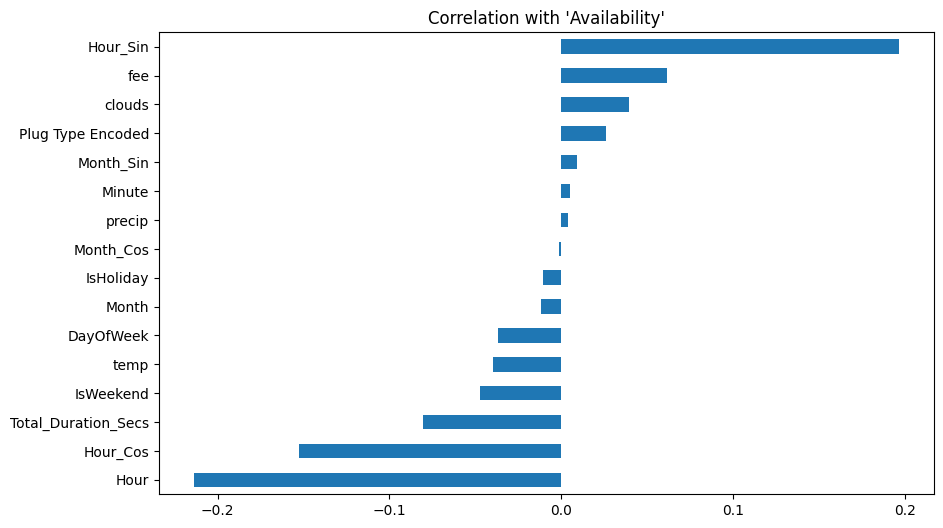

In [12]:
import matplotlib.pyplot as plt

# Drop the target column itself (since it will always have a perfect 1.0 correlation)
correlations.drop('Availability').sort_values().plot(kind='barh', figsize=(10, 6))

plt.title("Correlation with 'Availability'")
plt.show()

## Splitting training and testing data

In [7]:
split_idx = int(len(final_df) * 0.8)
train_df = final_df.iloc[:split_idx]
test_df = final_df.iloc[split_idx:]
train_df

,MAC Address,Total_Duration_Secs,Availability,temp,precip,clouds,Minute,Hour,DayOfWeek,Month,IsWeekend,IsHoliday,Hour_Sin,Hour_Cos,Month_Sin,Month_Cos,Plug Type Encoded,fee
0,000D:6F00:015A:9D76,2400.0,0,16.2,0.0,56,20,23,4,7,0,0,-2.588190e-01,0.965926,-0.5,-0.866025,0,0.0
1,000D:6F00:015A:9D76,29640.0,0,15.9,0.0,77,2,0,5,7,1,0,0.000000e+00,1.000000,-0.5,-0.866025,0,0.0
2,000D:6F00:015A:9D76,15452.0,1,15.4,0.0,97,16,8,5,7,1,0,8.660254e-01,-0.500000,-0.5,-0.866025,0,0.0
3,000D:6F00:015A:9D76,8220.0,0,21.5,0.0,2,34,12,5,7,1,0,1.224647e-16,-1.000000,-0.5,-0.866025,0,0.0
4,000D:6F00:015A:9D76,7404.0,1,24.1,0.0,2,51,14,5,7,1,0,-5.000000e-01,-0.866025,-0.5,-0.866025,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265054,0024:B100:0002:965D,10548.0,1,14.5,0.2,96,34,11,4,5,0,0,2.588190e-01,-0.965926,0.5,-0.866025,0,0.0
265055,000D:6F00:009E:D39E,6213.0,1,14.5,0.2,96,36,11,4,5,0,0,2.588190e-01,-0.965926,0.5,-0.866025,0,0.0
265056,0024:B100:0002:1262,4712.0,1,14.5,0.2,96,44,11,4,5,0,0,2.588190e-01,-0.965926,0.5,-0.866025,0,0.0
265057,0024:B100:0002:6B43,9545.0,1,14.5,0.2,96,49,11,4,5,0,0,2.588190e-01,-0.965926,0.5,-0.866025,0,1.0


In [9]:
train_df['Availability'].value_counts()

Availability
1    133417
0    131642
Name: count, dtype: int64

In [10]:
test_df['Availability'].value_counts()

Availability
0    34020
1    32245
Name: count, dtype: int64

## Separating data and label (Availability)

In [11]:
train_df_label_availability = train_df['Availability'].copy()
train_df_label_duration = train_df['Total_Duration_Secs'].copy()
train_df_data = train_df.drop(['Availability','Total_Duration_Secs'], axis = 1)

In [12]:
train_df_label_duration

0          2400.0
1         29640.0
2         15452.0
3          8220.0
4          7404.0
           ...   
265054    10548.0
265055     6213.0
265056     4712.0
265057     9545.0
265058     5940.0
Name: Total_Duration_Secs, Length: 265059, dtype: float64

## Pipeline

In [13]:
from sklearn.base import BaseEstimator, TransformerMixin

class CustomAttributeTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass
    def fit(self, X, y=None):
        return self
    def transform(self, data):
        data_copy = data.copy()

        print(data_copy)
        return data_copy

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import TargetEncoder

num_attribs = list(train_df_data.select_dtypes(include="number").columns)
cat_attribs = ['MAC Address']
print(num_attribs)

preprocessor = ColumnTransformer(
    transformers=[
        # 1. Target Encode ONLY the MAC Address
        ('mac_target', TargetEncoder(), cat_attribs),
        
        # 2. Scale the numerical/cyclical features
        ('std_scaler', StandardScaler(), num_attribs)
    ],
    # 3. Important: 'passthrough' keeps columns like IsWeekend/IsHoliday 
    # that are already binary/numeric without changing them.
    remainder='passthrough' 
)

full_pipeline = Pipeline([
    ('custom', CustomAttributeTransformer()),
    ('preprocessor', preprocessor)
])
# print(train_df_data)
train_df_prepared = full_pipeline.fit_transform(train_df_data, train_df_label_availability)
train_df_prepared

['Minute', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'IsHoliday', 'Hour_Sin', 'Hour_Cos', 'Month_Sin', 'Month_Cos', 'Plug Type Encoded', 'Station_Density', 'Is_Paid_Station']
                MAC Address  Minute  Hour  DayOfWeek  Month  IsWeekend  \
0       000D:6F00:015A:9D76      20    23          4      7          0   
1       000D:6F00:015A:9D76       2     0          5      7          1   
2       000D:6F00:015A:9D76      16     8          5      7          1   
3       000D:6F00:015A:9D76      34    12          5      7          1   
4       000D:6F00:015A:9D76      51    14          5      7          1   
...                     ...     ...   ...        ...    ...        ...   
265054  0024:B100:0002:965D      34    11          4      5          0   
265055  000D:6F00:009E:D39E      36    11          4      5          0   
265056  0024:B100:0002:1262      44    11          4      5          0   
265057  0024:B100:0002:6B43      49    11          4      5          0   
265058  00

array([[ 0.44130942, -0.54012136,  1.90194986, ..., -0.13741045,
        -0.57568711,  0.53123107],
       [ 0.44573936, -1.56937413, -3.02570973, ..., -0.13741045,
        -0.57568711,  0.53123107],
       [ 0.44130942, -0.7688442 , -1.31174118, ..., -0.13741045,
        -0.57568711,  0.53123107],
       ...,
       [ 0.51682736,  0.83221566, -0.66900297, ..., -0.13741045,
         0.56944086,  0.53123107],
       [ 0.53804295,  1.11811921, -0.66900297, ..., -0.13741045,
        -0.11763592,  0.53123107],
       [ 0.44687781,  1.23248062, -0.66900297, ..., -0.13741045,
        -0.11763592,  0.53123107]], shape=(265059, 14))

In [15]:
training_dataset = pd.DataFrame(
    train_df_prepared, columns= train_df_data.columns, index=train_df_data.index
)
training_dataset

,MAC Address,Minute,Hour,DayOfWeek,Month,IsWeekend,IsHoliday,Hour_Sin,Hour_Cos,Month_Sin,Month_Cos,Plug Type Encoded,Station_Density,Is_Paid_Station
0,0.441309,-0.540121,1.901950,0.557551,0.202542,-0.586675,-0.141126,0.004131,2.238262,-0.765549,-1.229483,-0.13741,-0.575687,0.531231
1,0.445739,-1.569374,-3.025710,1.072026,0.202542,1.704521,-0.141126,0.390509,2.295701,-0.765549,-1.229483,-0.13741,-0.575687,0.531231
2,0.441309,-0.768844,-1.311741,1.072026,0.202542,1.704521,-0.141126,1.683354,-0.232856,-0.765549,-1.229483,-0.13741,-0.575687,0.531231
3,0.445739,0.260409,-0.454757,1.072026,0.202542,1.704521,-0.141126,0.390509,-1.075708,-0.765549,-1.229483,-0.13741,-0.575687,0.531231
4,0.445170,1.232481,-0.026265,1.072026,0.202542,1.704521,-0.141126,-0.355916,-0.849867,-0.765549,-1.229483,-0.13741,-0.575687,0.531231
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265054,0.607341,0.260409,-0.669003,0.557551,-0.376931,-0.586675,-0.141126,0.776886,-1.018269,0.638256,-1.229483,-0.13741,-0.575687,0.531231
265055,0.435760,0.374770,-0.669003,0.557551,-0.376931,-0.586675,-0.141126,0.776886,-1.018269,0.638256,-1.229483,-0.13741,-0.117636,0.531231
265056,0.516827,0.832216,-0.669003,0.557551,-0.376931,-0.586675,-0.141126,0.776886,-1.018269,0.638256,-1.229483,-0.13741,0.569441,0.531231
265057,0.538043,1.118119,-0.669003,0.557551,-0.376931,-0.586675,-0.141126,0.776886,-1.018269,0.638256,-1.229483,-0.13741,-0.117636,0.531231


In [16]:
training_dataset['MAC Address'].value_counts()

MAC Address
0.441436    3960
0.445739    3889
0.441309    3874
0.440467    3833
0.445170    3822
            ... 
0.356674       4
1.000000       4
0.386214       3
0.416647       1
0.416647       1
Name: count, Length: 322, dtype: int64

## Training a Model (Model A availability)

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

log_reg = LogisticRegression()
log_reg.fit(training_dataset, train_df_label_availability)

log_reg_scores = cross_val_score(log_reg, training_dataset, train_df_label_availability, scoring="accuracy", cv=5)
print("Scores:", log_reg_scores)
# Scores: [0.60979519 0.6341528  0.63487326 0.63678469 0.64216609]

Scores: [0.58398099 0.60454237 0.60593828 0.60201464 0.60730792]


In [18]:
# from sklearn.tree import DecisionTreeClassifier

# dec_tree = DecisionTreeClassifier()
# dec_tree.fit(training_dataset, train_df_label_availability)
# dec_tree_scores = cross_val_score(dec_tree, training_dataset, train_df_label_availability, scoring="accuracy", cv=5)
# print("Scores:", dec_tree_scores)
# # Scores: [0.53147192 0.55778392 0.57656002 0.57189908 0.56837029]

In [19]:
# from sklearn.ensemble import RandomForestClassifier

# rd_forest = RandomForestClassifier()
# rd_forest.fit(training_dataset, train_df_label_availability)
# rd_forest_scores = cross_val_score(rd_forest, training_dataset, train_df_label_availability, scoring="accuracy", cv=5, n_jobs=-1)
# print("Scores:", rd_forest_scores)
# # Scores: [0.57402261 0.60361407 0.62008175 0.62062577 0.62206669]

In [20]:
import xgboost as xgb

xgb_cl = xgb.XGBClassifier()
xgb_cl.fit(training_dataset, train_df_label_availability)
xgb_cl_scores = cross_val_score(xgb_cl, training_dataset, train_df_label_availability, scoring="accuracy", cv=5, n_jobs=-1)
print("Scores:", xgb_cl_scores)
# Check recall and precision as well, SAVE THE MODEL
# Scores: [0.56155441 0.61545021 0.64344527 0.65241428 0.65263483

Scores: [0.55232777 0.57237984 0.61423829 0.61887874 0.62571919]


In [21]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get probabilities
y_pred_probs = xgb_cl.predict(training_dataset)

# Convert probabilities to class labels
# For binary classification:
y_pred = (y_pred_probs > 0.5).astype("int32")

print(classification_report(train_df_label_availability, y_pred))
# HOLY SHIT PLEASE FIX IT
cm = confusion_matrix(train_df_label_availability, y_pred)

              precision    recall  f1-score   support

           0       0.63      0.71      0.67    131642
           1       0.68      0.60      0.63    133417

    accuracy                           0.65    265059
   macro avg       0.66      0.65      0.65    265059
weighted avg       0.66      0.65      0.65    265059



## Grid Search

In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

param_grid_lr = {
    "penalty": ["l2"],
    "C": [0.01, 0.1, 1, 10],
    "solver": ["liblinear", "saga"],
    "max_iter": [100, 500]
}

param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10]
}

param_grid_rf = {
    "n_estimators": [100, 200],
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 6, 10],
    "learning_rate": [0.01, 0.1],
    "subsample": [0.8, 1.0]
}

models = [
    ("LogisticRegression", LogisticRegression(max_iter=1000, random_state=42), param_grid_lr),
    ("DecisionTree", DecisionTreeClassifier(random_state=42), param_grid_dt),
    ("RandomForest", RandomForestClassifier(random_state=42), param_grid_rf),
    ("XGBClassifier", xgb.XGBClassifier(eval_metric="logloss", random_state=42), param_grid_xgb),
]

best_results = {}
saved = False
if not saved:
    for name, estimator, param_grid in models:
        grid = GridSearchCV(estimator, param_grid, scoring="accuracy", cv=5, n_jobs=-1, verbose=1)
        grid.fit(training_dataset, train_df_label_availability)
        best_results[name] = {
            "best_score": grid.best_score_,
            "best_params": grid.best_params_,
            "best_estimator": grid.best_estimator_
        }
        print(f"{name}: best_score={grid.best_score_:.4f}")
        print("best_params=", grid.best_params_)
        print()
    # 25 minutes to run 
    # 10 minutes???? second run
    best_results


Fitting 5 folds for each of 16 candidates, totalling 80 fits


d:\University\Final_Project\Coding\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


LogisticRegression: best_score=0.6008
best_params= {'C': 10, 'max_iter': 100, 'penalty': 'l2', 'solver': 'saga'}

Fitting 5 folds for each of 24 candidates, totalling 120 fits
DecisionTree: best_score=0.6150
best_params= {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 2}

Fitting 5 folds for each of 24 candidates, totalling 120 fits


KeyboardInterrupt: 

In [ ]:
# # Fitting 5 folds for each of 16 candidates, totalling 80 fits
# LogisticRegression: best_score=0.6344
# best_params= {'C': 0.01, 'max_iter': 100, 'penalty': 'l2', 'solver': 'liblinear'}

# Fitting 5 folds for each of 24 candidates, totalling 120 fits
# DecisionTree: best_score=0.6510
# best_params= {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}

# Fitting 5 folds for each of 24 candidates, totalling 120 fits
# RandomForest: best_score=0.6478
# best_params= {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

# Fitting 5 folds for each of 24 candidates, totalling 120 fits
# d:\大學\Semester3\ml_HandsOn\Chapter2\env\Lib\site-packages\xgboost\training.py:199: UserWarning: [18:33:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
# Parameters: { "use_label_encoder" } are not used.

#   bst.update(dtrain, iteration=i, fobj=obj)
# XGBClassifier: best_score=0.6509
# best_params= {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}

In [ ]:
import joblib
saved = False
if not saved:
    joblib.dump(best_results['XGBClassifier']['best_estimator'], 'model/best_xgb_model.pkl')
    joblib.dump(best_results['XGBClassifier']['best_params'], 'model/best_xgb_params.pkl')

    joblib.dump(best_results['RandomForest']['best_estimator'], 'model/best_rf_model.pkl')
    joblib.dump(best_results['RandomForest']['best_params'], 'model/best_rf_params.pkl')

    joblib.dump(best_results['DecisionTree']['best_estimator'], 'model/best_dt_model.pkl')
    joblib.dump(best_results['DecisionTree']['best_params'], 'model/best_dt_params.pkl')

    joblib.dump(best_results['LogisticRegression']['best_estimator'], 'model/best_lr_model.pkl')
    joblib.dump(best_results['LogisticRegression']['best_params'], 'model/best_lr_params.pkl')

best_xgb_model = joblib.load('model/best_xgb_model.pkl')
best_xgb_params = joblib.load('model/best_xgb_params.pkl')

best_rf_model = joblib.load('model/best_rf_model.pkl')
best_rf_params = joblib.load('model/best_rf_params.pkl')

best_dt_model = joblib.load('model/best_dt_model.pkl')
best_dt_params = joblib.load('model/best_dt_params.pkl')

best_lr_model = joblib.load('model/best_lr_model.pkl')
best_lr_params = joblib.load('model/best_lr_params.pkl')

In [ ]:
# Assemble
from sklearn.ensemble import VotingClassifier

xgb_best = best_xgb_model
lr_best = best_lr_model
rf_best = best_rf_model
dc_best= best_dt_model

voting_clf = VotingClassifier(
    estimators=[('lr', lr_best), ('rf', rf_best), ('dc', dc_best), ('xgb', xgb_best)],
    voting='hard'
)
voting_clf.fit(training_dataset, train_df_label_availability)

d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001


## Test Set

In [ ]:
test_df_data = test_df.drop(['Availability','Total_Duration_Secs'], axis = 1)
testing_data_final = full_pipeline.transform(test_df_data)
testing_label = test_df['Availability'].copy()

                MAC Address  temp  precip  clouds  Minute  Hour  DayOfWeek  \
265059  0024:B100:0003:3A0A  14.5     0.2      96      56    11          4   
265060  0024:B100:0003:4209  14.5     0.2      96      56    11          4   
265061  0024:B100:0002:4233  15.1     0.1      71       1    12          4   
265062  0024:B100:0003:3A0A  15.1     0.1      71       2    12          4   
265063  000D:6F00:04B8:A128  15.1     0.1      71       4    12          4   
...                     ...   ...     ...     ...     ...   ...        ...   
331319  0024:B100:0003:3A0A  13.4     0.0      51      10    15          3   
331320  0024:B100:0003:CD37  13.4     0.0      51      16    15          3   
331321  0024:B100:0002:9B7F  13.4     0.0      51      51    15          3   
331322  0024:B100:0002:4233  13.5     0.0      50      48    16          3   
331323  0024:B100:0003:3A0A  11.6     0.0      24      19    18          3   

        Month  IsWeekend  IsHoliday      Hour_Sin      Hour_Cos

In [ ]:
from sklearn.metrics import accuracy_score

for clf in (lr_best, rf_best, dc_best, xgb_best, voting_clf):
    y_pred = clf.predict(testing_data_final)
    print(clf.__class__.__name__, accuracy_score(testing_label, y_pred))

d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


LogisticRegression 0.5994416358560326
RandomForestClassifier 0.6160718327925753
DecisionTreeClassifier 0.6035312759375235
XGBClassifier 0.6129178299253


d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
d:\大學\Final_Project\Coding\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


VotingClassifier 0.6140798309816645


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get probabilities
y_pred_probs = xgb_best.predict(testing_data_final)

# Convert probabilities to class labels
# For binary classification:
y_pred = (y_pred_probs > 0.5).astype("int32")

print(classification_report(testing_label, y_pred))
cm = confusion_matrix(testing_label, y_pred)
print(cm)

              precision    recall  f1-score   support

           0       0.63      0.61      0.62     34020
           1       0.60      0.62      0.61     32245

    accuracy                           0.61     66265
   macro avg       0.61      0.61      0.61     66265
weighted avg       0.61      0.61      0.61     66265

[[20762 13258]
 [12392 19853]]


## Neural Network

In [51]:
import numpy as np

def create_grouped_sequences(df, feature_cols, target_col, time_steps=12):
    X, y = [], []
    
    # Group by MAC address to ensure charger histories don't mix
    for mac, group in df.groupby('MAC Address'):
        # Extract the features and target for this specific charger
        group_features = group[feature_cols].values
        group_target = group[target_col].values
        
        # Only create sequences if the charger has enough data
        if len(group_features) > time_steps:
            for i in range(len(group_features) - time_steps):
                X.append(group_features[i : (i + time_steps)])
                y.append(group_target[i + time_steps])
    
    return np.array(X), np.array(y)

# Usage:
# Define which columns are your numbers/sin/cos features
features = training_dataset.columns
temp_df = pd.concat([training_dataset, train_df_label_availability], axis=1)  # Use the original DataFrame with all features and labels

X_final, y_final = create_grouped_sequences(temp_df, features, 'Availability', time_steps=12)
# time_steps=12 might represent the last hour if data is every 5 mins

In [68]:
X_final

array([[[ 0.37057509,  0.05838883,  0.13064194, ..., -0.06364635,
          1.43496993, -0.13741045],
        [ 0.37057509, -0.31069144, -0.17766792, ..., -0.06364635,
          1.43496993, -0.13741045],
        [ 0.37057509, -0.94340047, -0.17766792, ..., -0.06364635,
          1.43496993, -0.13741045],
        ...,
        [ 0.37057509,  0.51534535, -0.17766792, ...,  1.1520841 ,
          0.72103194, -0.13741045],
        [ 0.37057509, -0.34584194, -0.17766792, ...,  1.1520841 ,
          0.72103194, -0.13741045],
        [ 0.37057509,  1.09532863, -0.17766792, ...,  1.34015826,
          0.00709395, -0.13741045]],

       [[ 0.37057509, -0.31069144, -0.17766792, ..., -0.06364635,
          1.43496993, -0.13741045],
        [ 0.37057509, -0.94340047, -0.17766792, ..., -0.06364635,
          1.43496993, -0.13741045],
        [ 0.37057509, -0.85552421,  2.59712088, ..., -0.06364635,
          1.43496993, -0.13741045],
        ...,
        [ 0.37057509, -0.34584194, -0.17766792, ...,  

In [70]:
from tensorflow.keras.layers import Bidirectional, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l2

model = Sequential([
    # Layer 1: Bidirectional helps catch patterns from both directions
    Bidirectional(LSTM(units=128, return_sequences=True, kernel_regularizer=l2(0.01)), 
                  input_shape=(X_final.shape[1], X_final.shape[2])),
    BatchNormalization(),
    Dropout(0.3),
    
    # Layer 2: Increased units to handle the new weather/time features
    LSTM(units=64, return_sequences=False),
    BatchNormalization(),
    Dropout(0.3),
    
    # Layer 3: Wider Dense layer to interpret the LSTM states
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [71]:

testing_dataset = pd.DataFrame(
    testing_data_final, columns= test_df_data.columns, index=test_df_data.index
)
testing_dataset

,MAC Address,temp,precip,clouds,Minute,Hour,DayOfWeek,Month,IsWeekend,IsHoliday,Hour_Sin,Hour_Cos,Month_Sin,Month_Cos,Plug Type Encoded
265059,0.489740,-0.451293,0.438952,1.274752,1.518384,-0.669003,0.557551,-0.376931,-0.586675,-0.141126,0.776886,-1.018269,0.638256,-1.229483,-0.13741
265060,0.415851,-0.451293,0.438952,1.274752,1.518384,-0.669003,0.557551,-0.376931,-0.586675,-0.141126,0.776886,-1.018269,0.638256,-1.229483,-0.13741
265061,0.571848,-0.345842,0.130642,0.671963,-1.626555,-0.454757,0.557551,-0.376931,-0.586675,-0.141126,0.390509,-1.075708,0.638256,-1.229483,-0.13741
265062,0.489740,-0.345842,0.130642,0.671963,-1.569374,-0.454757,0.557551,-0.376931,-0.586675,-0.141126,0.390509,-1.075708,0.638256,-1.229483,-0.13741
265063,0.421178,-0.345842,0.130642,0.671963,-1.455013,-0.454757,0.557551,-0.376931,-0.586675,-0.141126,0.390509,-1.075708,0.638256,-1.229483,-0.13741
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331319,0.489740,-0.644621,-0.177668,0.189733,-1.111928,0.187981,0.043076,1.651225,-0.586675,-0.141126,-0.665095,-0.581977,-0.063646,1.434970,-0.13741
331320,0.503348,-0.644621,-0.177668,0.189733,-0.768844,0.187981,0.043076,1.651225,-0.586675,-0.141126,-0.665095,-0.581977,-0.063646,1.434970,-0.13741
331321,0.505815,-0.644621,-0.177668,0.189733,1.232481,0.187981,0.043076,1.651225,-0.586675,-0.141126,-0.665095,-0.581977,-0.063646,1.434970,-0.13741
331322,0.571848,-0.627046,-0.177668,0.165621,1.060938,0.402227,0.043076,1.651225,-0.586675,-0.141126,-0.902337,-0.232856,-0.063646,1.434970,-0.13741


In [72]:
temp_df = pd.concat([testing_dataset, testing_label], axis=1)

X_test_seq, y_test_seq = create_grouped_sequences(
    df=temp_df, 
    feature_cols=features, 
    target_col='Availability', 
    time_steps=12
)

In [ ]:
history = model.fit(
    X_final, y_final, 
    epochs=15,           # Number of times to go through the data
    batch_size=32,       # Number of samples per gradient update
    validation_data=(X_test_seq, y_test_seq),
    verbose=1            # Shows the progress bar and accuracy per epoch
)
# 35 minute

Epoch 1/15
8165/8165 ━━━━━━━━━━━━━━━━━━━━ 152s 18ms/step - accuracy: 0.5037 - loss: 0.7101 - val_accuracy: 0.4869 - val_loss: 0.6938
Epoch 2/15
8165/8165 ━━━━━━━━━━━━━━━━━━━━ 254s 31ms/step - accuracy: 0.5026 - loss: 0.6940 - val_accuracy: 0.4869 - val_loss: 0.6937
Epoch 3/15
2894/8165 ━━━━━━━━━━━━━━━━━━━━ 1:42 20ms/step - accuracy: 0.5045 - loss: 0.6936

In [ ]:
joblib.dump(model, 'model/lstm.pkl')

['model/lstm.pkl']

In [4]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import joblib

# Get probabilities
model = joblib.load('model/lstm.pkl')
y_pred_probs = model.predict(X_final)

# Convert probabilities to class labels
# For binary classification:
y_pred = (y_pred_probs > 0.5).astype("int32")

print(classification_report(y_final, y_pred))
# HOLY SHIT PLEASE FIX IT


NameError: name 'X_final' is not defined

In [ ]:
accuracy_score(y_final, y_pred)

NameError: name 'accuracy_score' is not defined